# Demonstration of tracker at large scale

While the main validation work is carried out using the 100-km images, we want to see the method in action on a larger scale. Ideally, we can look at data for all the regions in the paper. I've done an initial run on the Baffin Bay case. The segmentation was fast -- it took about 15 minutes to run for 1 month (April 2025). We'll look at those results first, then take a look at what is taking the tracker so long. (Perhaps the rotation calculation is the issue?) The main tracking calculation took 2 hours to run.

Baffin Bay results
* FSPipeline with LogLogQuadratic distance function, MinimumWeightMatching, and the default chained filter functions
* Mac Mini M4 with 24 GB memory
* Scene size 3500 by 6000 (about 750 km by 1500 km)
* Segmentation time: Approx 30 minutes
* Tracking time: Approx 90 minutes
* Another hour for the rotation computation

Odd results
* Some very high drift speeds ($>3$). Shouldn't that be impossible with the LogLogQuadratic Distance Threshold?
* Always missing lowest segment

In [1]:
import ultraplot as uplt
import skimage as ski
import pandas as pd
import numpy as np
import os


In [4]:
dataloc = "/Users/dwatkin2/Documents/research/packages/IceFloeTracker.jl/workflow/results/"

In [7]:
tracked = pd.read_csv(dataloc + 'baffin_bay-full.250m.2025-05-01.2025-05-15.FSPipeline.tracked.preproc5.csv')

In [8]:
dt_seconds = np.array([x.replace(' milliseconds', '') for x in tracked['Δt'].fillna('NaN')]).astype(float) / 1e3
tracked['dt_seconds'] = dt_seconds
tracked['dx_meters'] = tracked['Δx']
tracked['speed'] = tracked['dx_meters'] / tracked['dt_seconds']

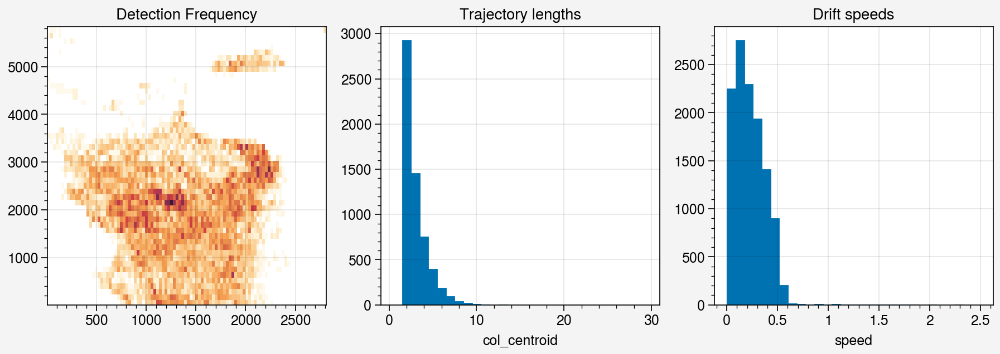

In [9]:
fig, axs = uplt.subplots(ncols=3, sharey=False, sharex=False)
ax = axs[0]
_ = ax.hist2d(tracked.col_centroid, 6000 - tracked.row_centroid, bins=[100, 50])
ax.format(title='Detection Frequency')

ax = axs[1]
ax.hist(tracked.groupby("ID").count()['col_centroid'], bins=np.arange(0.5, 30.5))
ax.format(title='Trajectory lengths')

ax = axs[2]
ax.hist(tracked['speed'], bins=np.linspace(0, 2.5, 30))
ax.format(title='Drift speeds')

In [10]:
landmask = ski.io.imread(dataloc + 'baffin_bay-full/250m.2025.landmask.tiff')

In [11]:
long_tracks = tracked.groupby("ID").filter(lambda x: len(x) > 5)

In [12]:
long_tracks.groupby("ID").area.mean()

ID
6        329.714286
23       366.833333
30       615.428571
42       477.166667
51      1156.166667
           ...     
5835     360.333333
5838     512.333333
5849     800.181818
5868    1376.000000
5870     816.142857
Name: area, Length: 369, dtype: float64

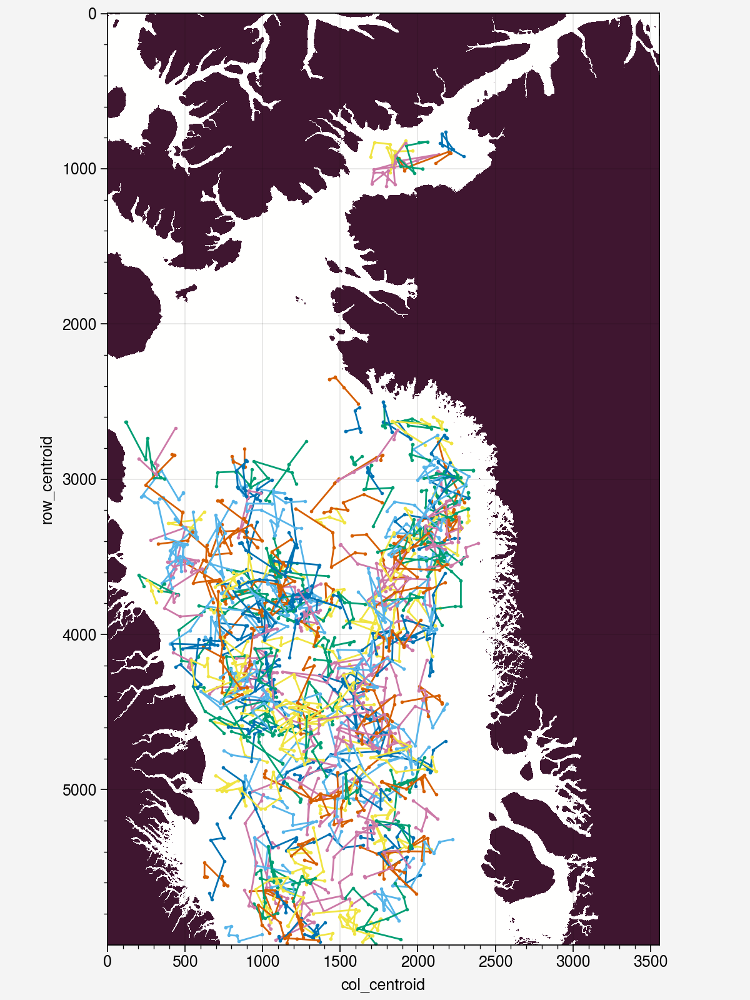

In [13]:
fig, ax = uplt.subplots(width=6, height=8)
ax.imshow(landmask)
for name, group in long_tracks.groupby("ID"):
    size = np.mean(group.area) # size in pixels
    speed = np.max(group.speed) 
    if size > 300:
        if speed < 1.5:
              ax.plot(group.col_centroid, group.row_centroid, m='.', ms=2, lw=1)
# ax.scatter(long_tracks.col_centroid, 6000 - long_tracks.row_centroid, ms=1)

ax.format(xreverse = False)

In [ ]:
# Without cleanup - what are the drift speeds?

In [16]:
import rasterio as rio
ref_img = rio.open(dataloc + 'baffin_bay-full.250m.2025-05-01.aqua/falsecolor.tiff')
left, bottom, right, top = ref_img.bounds

In [17]:
tracked['datetime'] = pd.to_datetime(tracked['passtime'])
x, y = ref_img.xy(tracked.row_centroid, tracked.col_centroid)
tracked['x_stere'] = x
tracked['y_stere'] = y

In [18]:
# Slow method, but need to do it individually
for name, group in tracked.groupby('ID'):
    tracked.loc[group.index, 'u'] = (group['x_stere'] - group['x_stere'].shift(1)) / group['dt_seconds']
    tracked.loc[group.index, 'v'] = (group['y_stere'] - group['y_stere'].shift(1)) / group['dt_seconds']

In [21]:
import pyproj
import scipy.stats as stats

##### Calculate Velocity Mean and Comparison with NSIDC ######
min_x = left
max_x = right
min_y = bottom
max_y = top

x_bins = np.arange(min_x, max_x, 25e3)
y_bins = np.arange(min_y, max_y, 25e3)
xc = 0.5*(x_bins[1:] + x_bins[:-1])
yc = 0.5*(y_bins[1:] + y_bins[:-1])
X, Y = np.meshgrid(xc, yc)

# Select data from 25 km bins for IFT and for NSIDC to compute monthly means
crs0 = pyproj.CRS('WGS84')
crs1 = pyproj.CRS('epsg:3413')
transformer_pstere = pyproj.Transformer.from_crs(crs1, crs_to=crs0, always_xy=True)

lon_grid, lat_grid = transformer_pstere.transform(np.ravel(X), np.ravel(Y))
lon_grid = np.reshape(lon_grid, X.shape)
lat_grid = np.reshape(lat_grid, Y.shape)

u_data = {}
v_data = {}
hist = {}
diffs_mean = {}
diffs_u = {}
diffs_v = {}

for month in [5]:
    u_data[month] = {}
    v_data[month] = {}
    hist[month] = {}
    for label, suffix in zip(['IFT'], ['']):
        sel = (tracked.datetime.dt.month == month) & (tracked['speed'] < 1.5) & (tracked['area'] > 400)
        x = tracked.x_stere
        y = tracked.y_stere
        u = tracked['u' + suffix] * 100
        v = tracked['v' + suffix] * 100
        
        hist2d = np.histogram2d(
            tracked.loc[sel, :].dropna(subset=['u'], axis=0)['x_stere'], 
            tracked.loc[sel, :].dropna(subset=['v'], axis=0)['y_stere'],
            bins=[x_bins, y_bins])
        
        df_hist = pd.DataFrame(hist2d[0], index=xc, columns=yc)
        hist[month] = df_hist
        
        u_mean, xedges, yedges, binnumber = stats.binned_statistic_2d(
            x[sel], y[sel], values=u[sel], statistic='mean', 
            bins=[x_bins, y_bins])
        v_mean, xedges, yedges, binnumber = stats.binned_statistic_2d(
            x[sel], y[sel], values=v[sel], statistic='mean', 
            bins=[x_bins, y_bins])

        # # Rotation from Earth coordinates to the north polar stereographic grid for display
        U_nps = u_mean.T * np.sin(np.deg2rad(lon_grid + 45)) + v_mean.T * np.cos(np.deg2rad(lon_grid + 45))
        V_nps = v_mean.T * np.cos(np.deg2rad(lon_grid + 45)) - u_mean.T * np.sin(np.deg2rad(lon_grid + 45))
        u_data[month][label] = pd.DataFrame(U_nps.T, index=xc, columns=yc)
        v_data[month][label] = pd.DataFrame(V_nps.T, index=xc, columns=yc)


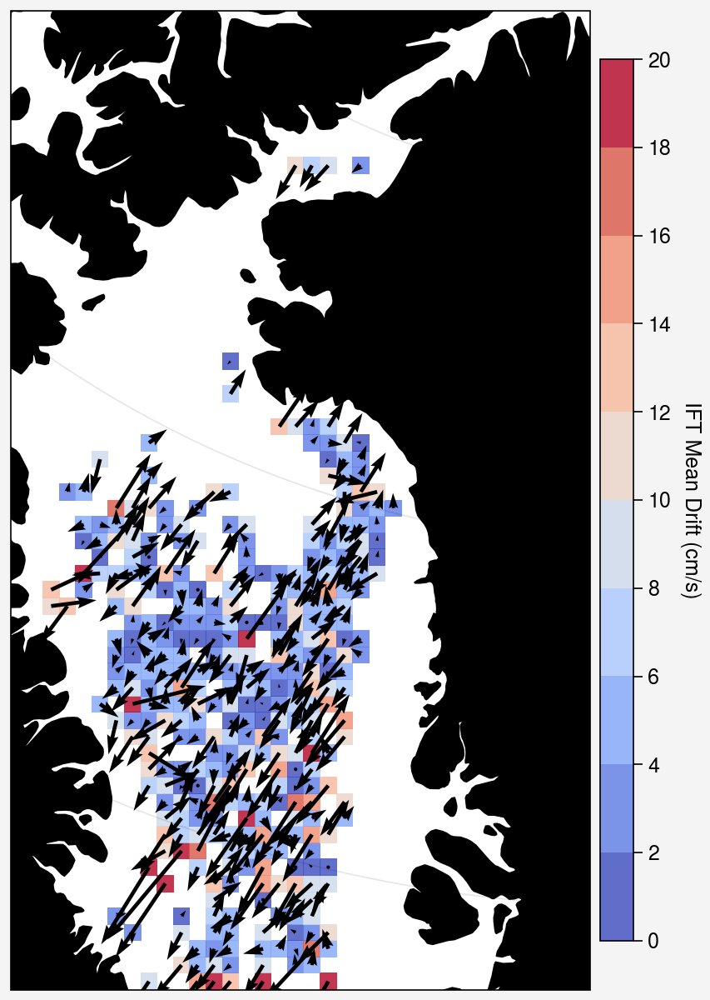

In [23]:
import cartopy.crs as ccrs
uplt.rc['reso'] = 'med'
uplt.rc['geo.round'] = False
xspacing = 1
yspacing = 1
crs = ccrs.NorthPolarStereo(central_longitude=-45, true_scale_latitude=70)
fig, ax = uplt.subplots(height=6, proj='npstere',
                         proj_kw={'lon_0': -45}, ncols=1, nrows=1, share=False)
ax.set_extent([left, right, bottom, top], crs=crs)  
ax.format(land=True, coast=True, lonlocator=np.arange(-30, 30, 10),
          latmax=85, latlocator=np.arange(55, 85, 5), 
       landzorder=0, landcolor='k', facecolor='w')

idx_data = hist[month] > 10
speed = np.sqrt(u_data[month]['IFT'] **2 + v_data[month]['IFT'] **2)
c1 = ax.pcolor(lon_grid, lat_grid, speed.where(idx_data).T.values, vmin=0, vmax=20,
       transform=ccrs.PlateCarree(), cmap='coolwarm', alpha=0.8)

ax.quiver(lon_grid[::xspacing, ::yspacing], lat_grid[::xspacing, ::yspacing],
          u_data[month]['IFT'].where(idx_data).T.values[::xspacing, ::yspacing],
          v_data[month]['IFT'].where(idx_data).T.values[::xspacing, ::yspacing],
       transform=ccrs.PlateCarree(), color='k', scale=150, width=1/150)
ax.colorbar(c1, label='IFT Mean Drift (cm/s)', loc='r', shrink=0.9)

Experiment results
* Noisy drift field needs to be addressed
* Reducing shapes which intersect the boundaries will likely improve processing speed
* Post-segmentation cleanup required
  * Clearing intersection with land mask would reduce a ton of false positives
* Drift field does not appear particularly coherent
* Mysterious lack of data from lower tiles. Investigate the cloud masks and the ice masks

# Checking the drift in pairs

In [27]:
dataloc + 'baffin_bay-full.250m.2025-05-01.{s}/FSPipeline/ice_mask.tiff'.format(s=satellites[1])

'/Users/dwatkin2/Documents/research/packages/IceFloeTracker.jl/workflow/results/baffin_bay-full.250m.2025-05-01.terra/FSPipeline/ice_mask.tiff'

In [115]:
satellites = ['aqua', 'terra']

tc_imgs = {s: ski.io.imread(dataloc + 'baffin_bay-full.250m.2025-05-06.{s}/truecolor.tiff'.format(s=s)) for s in satellites}
ice_masks = {s: ski.io.imread(dataloc + 'baffin_bay-full.250m.2025-05-06.{s}/FSPipeline/ice_mask.tiff'.format(s=s)) for s in satellites}
cloud_masks = {s: ski.io.imread(dataloc + 'baffin_bay-full.250m.2025-05-06.{s}/FSPipeline/cloud_mask.tiff'.format(s=s)) for s in satellites}
labels = {s: ski.io.imread(dataloc + 'baffin_bay-full.250m.2025-05-06.{s}/FSPipeline/labels_map.tiff'.format(s=s)) for s in satellites}

# Plotting TBD
- Overlay tracks on image

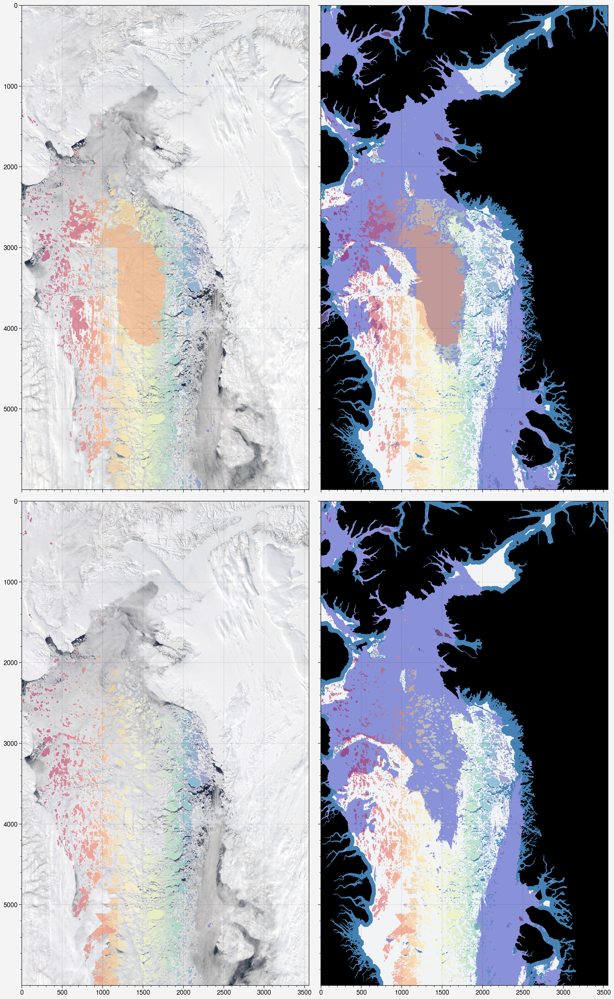

In [116]:
fig, axs = uplt.subplots(width=12, ncols=2, nrows=2)
for idx, sat in enumerate(satellites):
    tc = tc_imgs[sat]
    land_mask = landmask
    ice_mask = ice_masks[sat]
    cloud_mask = cloud_masks[sat]
    labeled = labels[sat]
    
    ax = axs[idx, 0]
    ax.imshow(tc)
    ax.imshow(np.ma.masked_array(labeled, labeled==0), cmap='spectral', alpha=0.5)
    
    ax = axs[idx, 1]
    ax.imshow(np.ma.masked_array(land_mask, land_mask==1), color='steelblue')
    ax.imshow(np.ma.masked_array(land_mask, land_mask==0), color='k')
    ax.imshow(np.ma.masked_array(ice_mask, ice_mask==0), color='gray1')
    ax.imshow(np.ma.masked_array(cloud_mask, cloud_mask==0), color='lilac', alpha=0.5)
    ax.imshow(np.ma.masked_array(labeled, labeled==0), cmap='spectral', alpha=0.5)
  

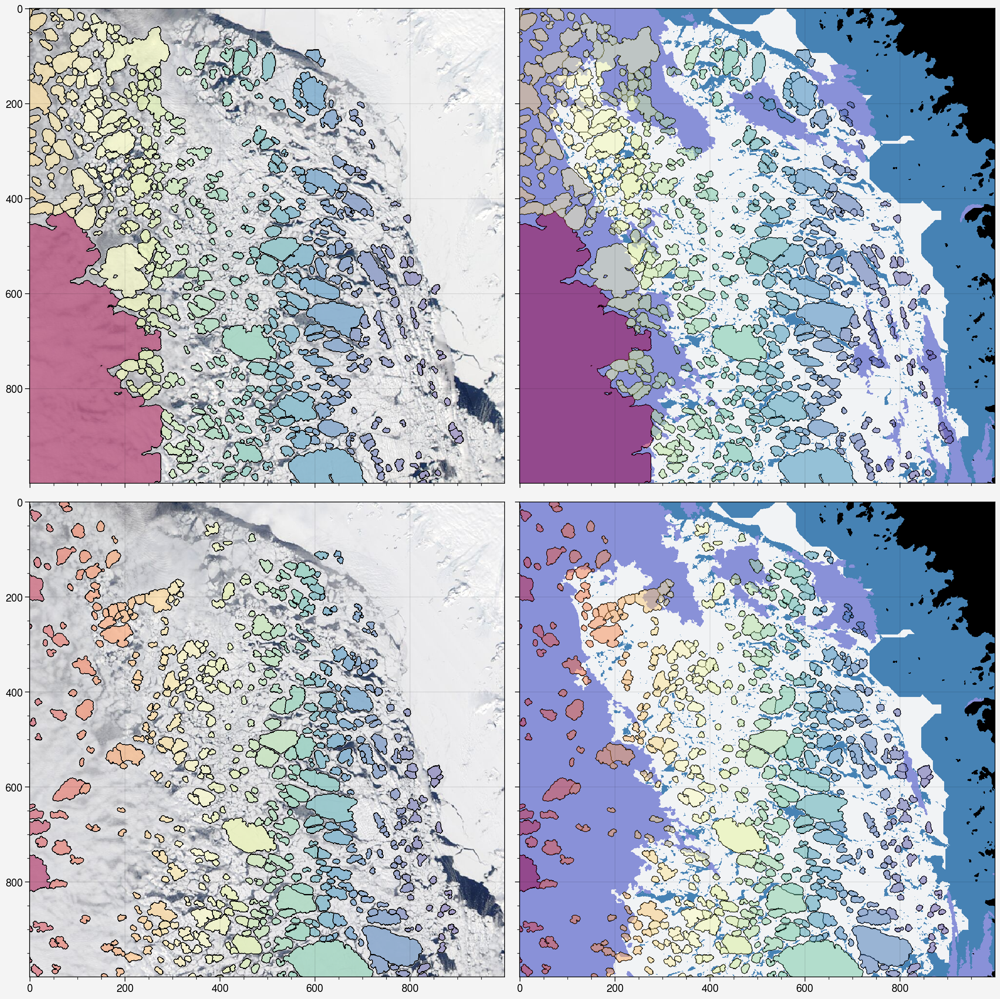

In [118]:
# for images these are reversed
ymin = 2500
ymax = 3500
xmin = 1500
xmax = 2500

fig, axs = uplt.subplots(width=12, ncols=2, nrows=2)
for idx, sat in enumerate(satellites):
    tc = tc_imgs[sat][ymin:ymax, xmin:xmax]
    land_mask = landmask[ymin:ymax, xmin:xmax]
    ice_mask = ice_masks[sat][ymin:ymax, xmin:xmax]
    cloud_mask = cloud_masks[sat][ymin:ymax, xmin:xmax]
    labeled = labels[sat][ymin:ymax, xmin:xmax]
    bdry = ski.segmentation.find_boundaries(labeled)
    
    ax = axs[idx, 0]
    ax.imshow(tc)
    ax.imshow(np.ma.masked_array(labeled, labeled==0), cmap='spectral', alpha=0.5)
    ax.imshow(np.ma.masked_array(bdry.astype(int), ~bdry), color='k')
    
    ax = axs[idx, 1]
    ax.imshow(np.ma.masked_array(land_mask, land_mask==1), color='steelblue')
    ax.imshow(np.ma.masked_array(land_mask, land_mask==0), color='k')
    ax.imshow(np.ma.masked_array(ice_mask, ice_mask==0), color='gray1')
    ax.imshow(np.ma.masked_array(cloud_mask, cloud_mask==0), color='lilac', alpha=0.5)
    ax.imshow(np.ma.masked_array(bdry.astype(int), ~bdry), color='k')
    ax.imshow(np.ma.masked_array(labeled, labeled==0), cmap='spectral', alpha=0.5)
    
    
    
    
    # fig.save('../figures/test_img_baffin`.png', dpi=300)

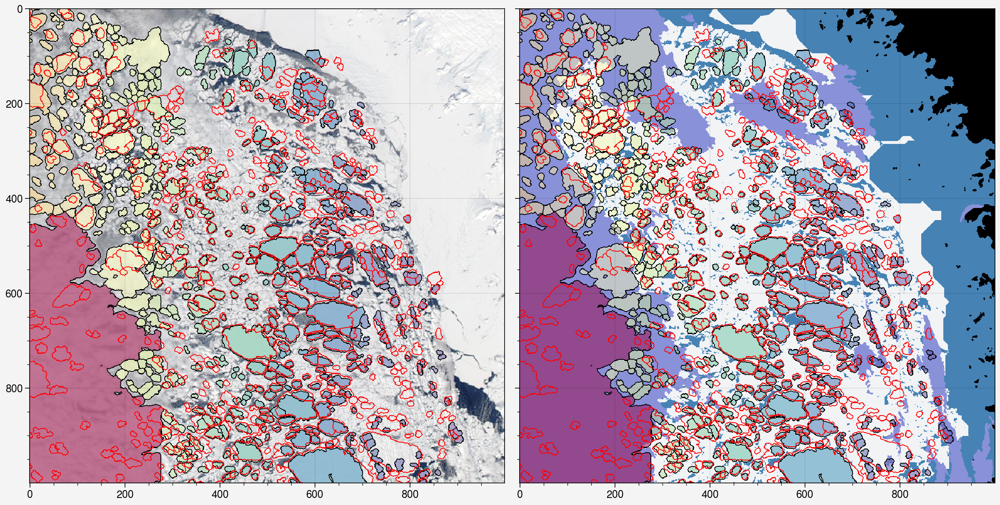

In [119]:
# for images these are reversed
ymin = 2500
ymax = 3500
xmin = 1500
xmax = 2500

fig, axs = uplt.subplots(width=12, ncols=2, nrows=1)
sat = 'aqua'
tc = tc_imgs[sat][ymin:ymax, xmin:xmax]
land_mask = landmask[ymin:ymax, xmin:xmax]
ice_mask = ice_masks[sat][ymin:ymax, xmin:xmax]
cloud_mask = cloud_masks[sat][ymin:ymax, xmin:xmax]
labeled = labels[sat][ymin:ymax, xmin:xmax]
ax = axs[0]
ax.imshow(tc)
ax.imshow(np.ma.masked_array(labeled, labeled==0), cmap='spectral', alpha=0.5)

ax = axs[1]
ax.imshow(np.ma.masked_array(land_mask, land_mask==1), color='steelblue')
ax.imshow(np.ma.masked_array(land_mask, land_mask==0), color='k')
ax.imshow(np.ma.masked_array(ice_mask, ice_mask==0), color='gray1')
ax.imshow(np.ma.masked_array(cloud_mask, cloud_mask==0), color='lilac', alpha=0.5)
ax.imshow(np.ma.masked_array(bdry.astype(int), ~bdry), color='k')
ax.imshow(np.ma.masked_array(labeled, labeled==0), cmap='spectral', alpha=0.5)

colors = ['k', 'r']
for ax in axs:
    for idx, sat in enumerate(satellites):
        labeled = labels[sat][ymin:ymax, xmin:xmax]
        bdry = ski.segmentation.find_boundaries(labeled)
        ax.imshow(np.ma.masked_array(bdry.astype(int), ~bdry), color=colors[idx])
    

As shown in the above figure, persistence across a pair of images is an excellent test of whether an object is actually a sea ice floe. If drift speeds are low relative to the floe size, ice floes tend to overlap. So, a good match across a pair of days gives confidence that the shape is actually an ice floe.

Some other clues: if an object's entire border is the tile border, it should be rejected.

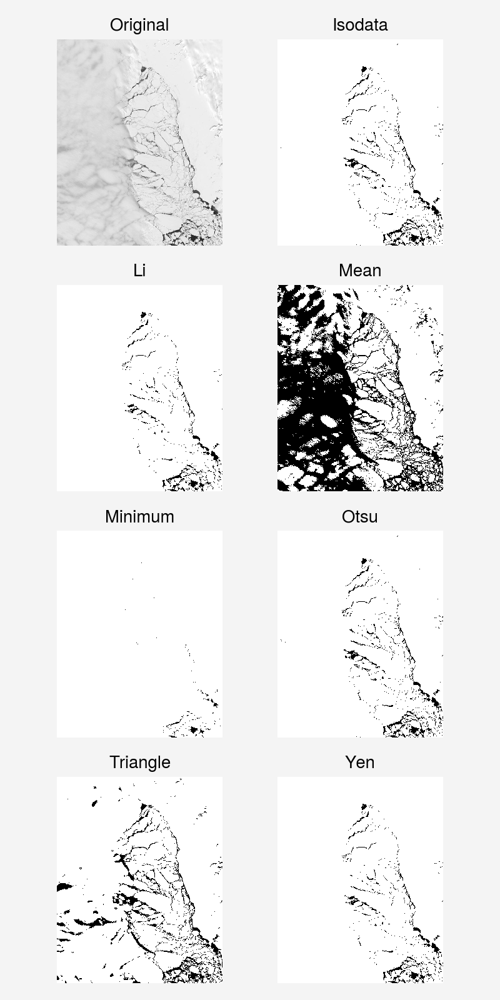

In [113]:
ymin = 2500
ymax = 3500
xmin = 1700
xmax = 2500
gray = tc_imgs[sat][ymin:ymax, xmin:xmax][:,:,1]

fig, ax = ski.filters.try_all_threshold(gray, figsize=(4, 8), verbose=False)

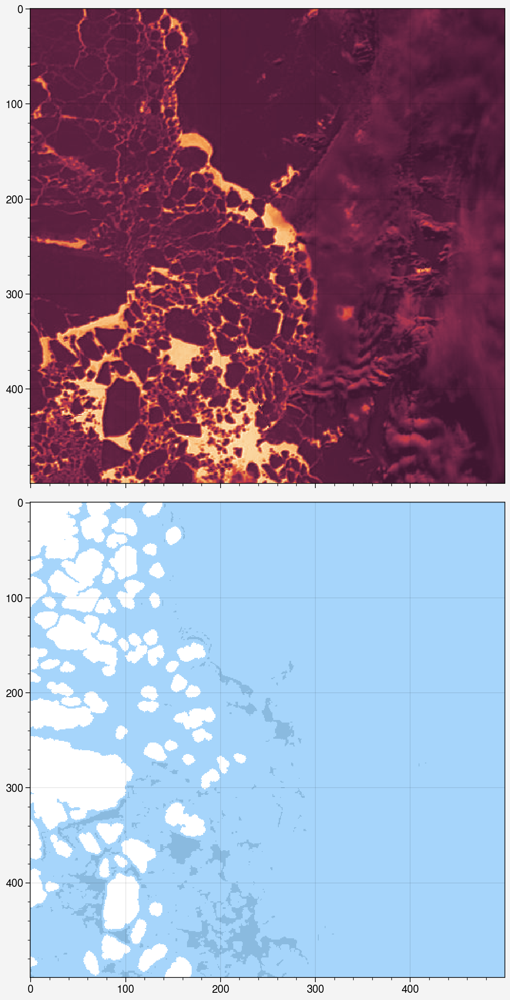

In [108]:
fig, axs = uplt.subplots(width=6, ncols=1, nrows=2)
sat = 'aqua'
gray = tc_imgs[sat][ymin:ymax, xmin:xmax][:,:,1]
labeled = labels[sat][ymin:ymax, xmin:xmax]
axs[0].imshow(gray)
axs[1].imshow(np.ma.masked_array(gray, gray > 75), color='gray', alpha=0.5)
axs[1].imshow(np.ma.masked_array(labeled, labeled > 0), color='blue4', alpha=0.5)

In [74]:
from skimage import data, feature
img = gray
blobs = feature.blob_dog(img, threshold=.05, min_sigma=10, max_sigma=40)

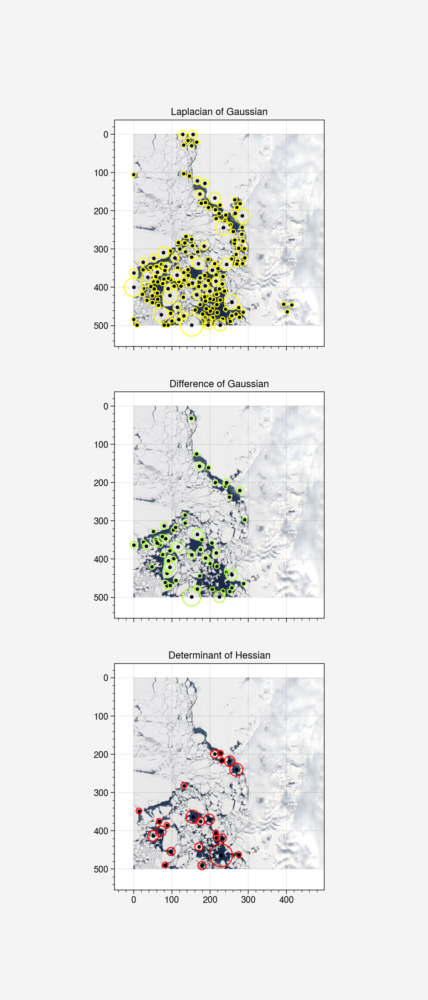

In [100]:
from skimage.feature import blob_dog, blob_log, blob_doh
from skimage.color import rgb2gray
import matplotlib.pyplot as plt

ymin = 3100
ymax = 3600
xmin = 2200
xmax = 2700

image = tc_imgs[sat][ymin:ymax, xmin:xmax]
image_gray = rgb2gray(image[:,:,0:3])

blobs_log = blob_log(image_gray, max_sigma=30, num_sigma=10, threshold=0.1)

# Compute radii in the 3rd column.
blobs_log[:, 2] = blobs_log[:, 2] * np.sqrt(2)

blobs_dog = blob_dog(image_gray, max_sigma=30, threshold=0.1)
blobs_dog[:, 2] = blobs_dog[:, 2] * np.sqrt(2)

blobs_doh = blob_doh(image_gray, max_sigma=30, threshold=0.01)

blobs_list = [blobs_log, blobs_dog, blobs_doh]
colors = ['yellow', 'lime', 'red']
titles = ['Laplacian of Gaussian', 'Difference of Gaussian', 'Determinant of Hessian']
sequence = zip(blobs_list, colors, titles)

fig, axes = plt.subplots(3, 1, figsize=(6, 14), sharex=True, sharey=True)
ax = axes.ravel()

for idx, (blobs, color, title) in enumerate(sequence):
    ax[idx].set_title(title)
    ax[idx].imshow(image)
    for blob in blobs:
        y, x, r = blob
        if r > 5:
            c = plt.Circle((x, y), r, color=color, linewidth=1, fill=False)
            ax[idx].scatter(x, y, marker='.', color='k')
            ax[idx].add_patch(c)

# TODO
1. Apply land mask after cloud mask creation so that islands aren't treated as holes
2. Don't use the coastal buffer on the preliminary ice mask
3. Check the maximum size of returned objects in relation to the tile size
4. Check which objects are tracked
5. Add vectors for tracked floes
6. Describe tracking in the TGRS paper as a method to identify confident sea ice floes

## Maybe TODO
1. Use the local binary patterns texture descriptor to find edge pixels, interior pixels

